# Desafio: árvore de decisão do zero
**Objetivo:** aprender perguntas a partir dos exemplos de treino e usá-las para prever se um cliente comprou.

Construiremos nossa árvore com Python e NumPy. O scikit-learn será usado para separar os dados, calcular métricas e comparar o resultado com uma árvore pronta.

## 1. Importar as bibliotecas
Preparamos as ferramentas de cálculo, visualização e comparação. A construção da nossa árvore será feita nas próximas etapas.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier

## 2. Criar os dados e separar treino e teste
Usamos os 24 clientes dos slides: `X` contém idade e visitas à loja; `y` indica se comprou (1) ou não (0). Reservamos seis clientes para avaliar a árvore depois do treino.

In [2]:
#criando o dataset da aula
X = np.array([
    [19, 1], [25, 6], [22, 6], [28, 8], [24, 2], [31, 3],
    [27, 3], [34, 9], [35, 2], [36, 5], [41, 3], [39, 8],
    [47, 1], [42, 6], [55, 4], [45, 10], [58, 8], [29, 4],
    [61, 6], [48, 7], [64, 9], [33, 11], [38, 4], [52, 9]
])
y = np.array([
    0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
    0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1
])
nomes = ["Idade", "Visitas"]

#separando os dados sem mudar a proporção das classes
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)
print("Classes no treino:", np.bincount(y_treino))
print("Classes no teste:", np.bincount(y_teste))

Treino: (18, 2) | Teste: (6, 2)
Classes no treino: [9 9]
Classes no teste: [3 3]


## 3. Calcular a impureza de Gini
Antes de escolher uma pergunta, precisamos medir a mistura das classes. A função retorna zero para um grupo puro e valores maiores para grupos misturados.

In [3]:
def gini(y):
    if len(y) == 0:
        return 0.0
    classes, contagens = np.unique(y, return_counts=True)
    proporcoes = contagens / len(y)
    return 1.0 - np.sum(proporcoes ** 2)


print("Gini do treino:", gini(y_treino))

Gini do treino: 0.5


## 4. Avaliar os dois lados de uma divisão
Cada pergunta separa os exemplos em dois grupos. Usamos o Gini ponderado pelo tamanho de cada grupo para avaliar a divisão inteira; essa função será usada na busca do melhor corte.

In [4]:
def gini_ponderado(y_esq, y_dir):
    n = len(y_esq) + len(y_dir)
    if n == 0:
        return 0.0
    peso_esq = len(y_esq) / n
    peso_dir = len(y_dir) / n
    return peso_esq * gini(y_esq) + peso_dir * gini(y_dir)

## 5. Encontrar o melhor corte
Testamos os pontos médios entre valores distintos de cada característica e escolhemos o menor Gini ponderado. Cortes que deixariam poucos exemplos em um dos lados são descartados.

In [5]:
def melhor_divisao(X, y, min_samples_leaf=1):
    melhor_coluna = None
    melhor_limiar = None
    menor_impureza = np.inf

    for coluna in range(X.shape[1]):
        valores = np.unique(X[:, coluna])
        limiares = (valores[:-1] + valores[1:]) / 2

        for limiar in limiares:
            mascara = X[:, coluna] <= limiar
            y_esq, y_dir = y[mascara], y[~mascara]
            if len(y_esq) < min_samples_leaf or len(y_dir) < min_samples_leaf:
                continue

            impureza = gini_ponderado(y_esq, y_dir)
            if impureza < menor_impureza:
                melhor_coluna = coluna
                melhor_limiar = limiar
                menor_impureza = impureza

    return melhor_coluna, melhor_limiar, menor_impureza


coluna, limiar, impureza = melhor_divisao(X_treino, y_treino)
print(f"Melhor pergunta inicial: {nomes[coluna]} <= {limiar}")
print(f"Gini ponderado: {impureza:.4f}")
print(f"Ganho: {gini(y_treino) - impureza:.4f}")

Melhor pergunta inicial: Visitas <= 3.5
Gini ponderado: 0.3571
Ganho: 0.1429


## 6. Representar nós e folhas
Agora precisamos guardar as perguntas e seus caminhos. Um nó interno terá dois filhos; uma folha não terá filhos e devolverá a classe majoritária do grupo.

In [6]:
class No:
    def __init__(self, classe, n_samples, impureza):
        self.classe = classe
        self.n_samples = n_samples
        self.impureza = impureza
        self.feature = None
        self.threshold = None
        self.left = None
        self.right = None

    def eh_folha(self):
        return self.left is None and self.right is None

## 7. Construir a árvore e implementar as previsões
`fit` repete a busca de cortes em grupos menores até um critério de parada; essa repetição é a recursividade. Depois, `predict` percorre as perguntas aprendidas e `score` calcula a proporção de acertos.

In [7]:
class ArvoreDecisaoDoZero:
    def __init__(self, max_depth=3, min_samples_split=2, min_samples_leaf=1):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf

    def _criar_folha(self, y):
        classes, contagens = np.unique(y, return_counts=True)
        classe = classes[np.argmax(contagens)]
        return No(classe=classe, n_samples=len(y), impureza=gini(y))

    def _construir(self, X, y, profundidade):
        no = self._criar_folha(y)

        #parando se o grupo for puro, a árvore atingir o limite ou houver poucos exemplos
        if (no.impureza == 0 or profundidade >= self.max_depth
                or len(y) < self.min_samples_split):
            return no

        coluna, limiar, impureza = melhor_divisao(X, y, self.min_samples_leaf)

        #parando se nenhum corte válido reduzir a impureza
        if coluna is None or no.impureza - impureza <= 1e-12:
            return no

        #criando os dois filhos com grupos menores
        mascara = X[:, coluna] <= limiar
        no.feature = coluna
        no.threshold = limiar
        no.left = self._construir(X[mascara], y[mascara], profundidade + 1)
        no.right = self._construir(X[~mascara], y[~mascara], profundidade + 1)
        return no

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.raiz = self._construir(X, y, profundidade=0)
        return self

    def _prever_amostra(self, amostra, no):
        if no.eh_folha():
            return no.classe
        if amostra[no.feature] <= no.threshold:
            return self._prever_amostra(amostra, no.left)
        return self._prever_amostra(amostra, no.right)

    def predict(self, X):
        return np.array([
            self._prever_amostra(amostra, self.raiz)
            for amostra in np.asarray(X, dtype=float)
        ])

    def score(self, X, y):
        return np.mean(self.predict(X) == np.asarray(y))

## 8. Treinar e avaliar as previsões
A classe está pronta: treinamos somente com os exemplos de treino e prevemos os seis clientes reservados. A acurácia mostra os acertos; na matriz de confusão, linhas são classes reais e colunas são previstas, na ordem 0 e 1.

In [8]:
modelo = ArvoreDecisaoDoZero(
    max_depth=3, min_samples_split=2, min_samples_leaf=1
)
modelo.fit(X_treino, y_treino)
y_previsto = modelo.predict(X_teste)
acuracia_treino = modelo.score(X_treino, y_treino)
acuracia_teste = modelo.score(X_teste, y_teste)

print("Real:    ", y_teste)
print("Previsto:", y_previsto)
print(f"Acurácia no treino: {acuracia_treino:.2%}")
print(f"Acurácia no teste: {acuracia_teste:.2%}")
print("Matriz de confusão (ordem: 0, 1):")
print(confusion_matrix(y_teste, y_previsto, labels=[0, 1]))

Real:     [0 1 1 1 0 0]
Previsto: [0 1 1 0 0 0]
Acurácia no treino: 94.44%
Acurácia no teste: 83.33%
Matriz de confusão (ordem: 0, 1):
[[3 0]
 [1 2]]


## 9. Imprimir a estrutura aprendida
Vamos mostrar quais perguntas o treinamento escolheu. A indentação representa a profundidade, e os caminhos “Sim” e “Não” levam até as folhas com as classes previstas.

In [9]:
def imprimir_arvore(no, nomes, nivel=0, lado="Raiz"):
    espaco = "    " * nivel
    if no.eh_folha():
        print(f"{espaco}[{lado}] Classe {no.classe} | amostras: {no.n_samples}")
        return

    print(f"{espaco}[{lado}] {nomes[no.feature]} <= {no.threshold:g}?")
    imprimir_arvore(no.left, nomes, nivel + 1, "Sim")
    imprimir_arvore(no.right, nomes, nivel + 1, "Não")


imprimir_arvore(modelo.raiz, nomes)

[Raiz] Visitas <= 3.5?
    [Sim] Classe 0 | amostras: 4
    [Não] Idade <= 53?
        [Sim] Idade <= 23.5?
            [Sim] Classe 0 | amostras: 1
            [Não] Classe 1 | amostras: 10
        [Não] Classe 0 | amostras: 3


## 10. Visualizar as regiões de decisão
As cores de fundo mostram a classe que a árvore prevê para cada combinação de idade e visitas. Os pontos mostram os clientes reais: círculos são treino e X são teste; o gráfico usa o modelo já treinado.

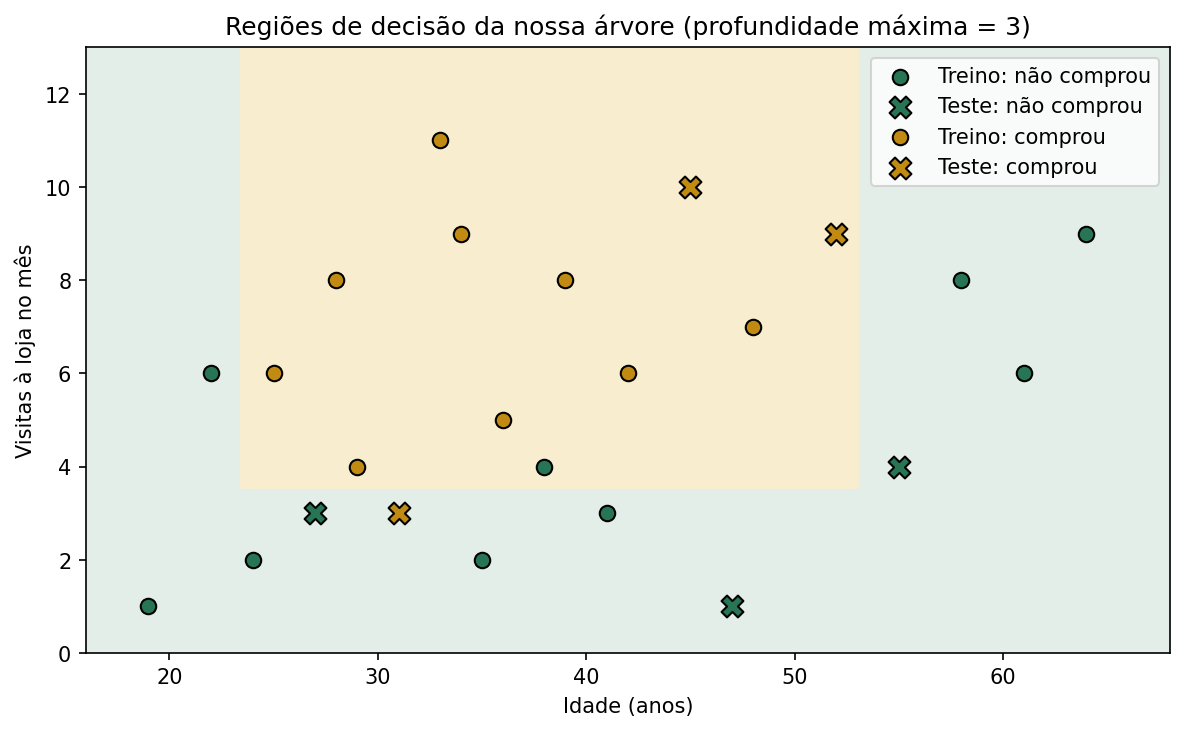

In [10]:
#criando combinações de idade e visitas para desenhar as previsões
xx, yy = np.meshgrid(np.linspace(16, 68, 250), np.linspace(0, 13, 250))
grade = np.column_stack([xx.ravel(), yy.ravel()])
regioes = modelo.predict(grade).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 5))
ax.contourf(xx, yy, regioes, levels=[-0.5, 0.5, 1.5], colors=["#e4eee9", "#f8edcf"])

for classe, cor, nome in [(0, "#287556", "não comprou"), (1, "#c18b13", "comprou")]:
    treino = y_treino == classe
    teste = y_teste == classe
    ax.scatter(X_treino[treino, 0], X_treino[treino, 1], color=cor,
               edgecolors="black", s=55, label=f"Treino: {nome}")
    ax.scatter(X_teste[teste, 0], X_teste[teste, 1], color=cor,
               edgecolors="black", marker="X", s=110, label=f"Teste: {nome}")

ax.set_xlabel("Idade (anos)")
ax.set_ylabel("Visitas à loja no mês")
ax.set_title("Regiões de decisão da nossa árvore (profundidade máxima = 3)")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Comparar com o scikit-learn
Treinamos a árvore pronta com os mesmos dados e limites para comparar as previsões e acurácias. Em outros dados, empates entre cortes e detalhes numéricos podem produzir estruturas diferentes, mesmo com implementações corretas.

In [11]:
modelo_sklearn = DecisionTreeClassifier(
    criterion="gini", max_depth=3, min_samples_split=2,
    min_samples_leaf=1, random_state=0
)
modelo_sklearn.fit(X_treino, y_treino)
y_previsto_sklearn = modelo_sklearn.predict(X_teste)
acuracia_sklearn = accuracy_score(y_teste, y_previsto_sklearn)

print("Previsões da nossa árvore:", y_previsto)
print("Previsões do scikit-learn:", y_previsto_sklearn)
print(f"Acurácia da nossa árvore: {acuracia_teste:.2%}")
print(f"Acurácia do scikit-learn: {acuracia_sklearn:.2%}")
print("Mesmas previsões:", np.array_equal(y_previsto, y_previsto_sklearn))

Previsões da nossa árvore: [0 1 1 0 0 0]
Previsões do scikit-learn: [0 1 1 0 0 0]
Acurácia da nossa árvore: 83.33%
Acurácia do scikit-learn: 83.33%
Mesmas previsões: True


## Pequena análise dos resultados
A árvore acertou 5 dos 6 clientes de teste (83.33%), com 94.44% de acurácia no treino. O scikit-learn obteve 83.33% no mesmo teste, com as mesmas previsões. Um erro ocorreu no cliente de 31 anos e 3 visitas: a classe real era 1 e a prevista foi 0. O dataset é pequeno e o teste tem só seis exemplos; esse resultado não garante o mesmo desempenho em outros clientes.